## CSC311 Project Methodology

#### 1. Data Process Pipelines & Setup

In [1]:
import json
import pandas as pd
import numpy as np

def compute_tfidf_inference(text_series, prefix, saved_idf):
    """Applies saved IDF weights to new text data."""
    docs = text_series.fillna('null').astype(str).str.lower().str.split(r'\W+')
    docs = docs.apply(lambda x: [w for w in x if w])
    
    tfidf_matrix = []
    for doc in docs:
        doc_len = len(doc)
        doc_counts = {}
        for w in doc:
            doc_counts[w] = doc_counts.get(w, 0) + 1
            
        row = {}
        for word, idf_val in saved_idf.items():
            tf = doc_counts.get(word, 0) / doc_len if doc_len > 0 else 0
            row[f'{prefix}_{word}'] = tf * idf_val
        tfidf_matrix.append(row)
    return pd.DataFrame(tfidf_matrix, index=text_series.index)

def process_unseen_data(input_filepath, output_filepath):
    # 1. Load data and JSON metadata
    df = pd.read_csv(input_filepath)
    with open('processed/imputed_medians.json', 'r') as f:
        medians = json.load(f)
    with open('processed/tfidf_metadata.json', 'r') as f:
        tfidf_metadata = json.load(f)
    with open('processed/scaling_params.json', 'r') as f:
        scaling_params = json.load(f)
        
    expected_features = list(scaling_params.keys())

    # 2. Rename columns using exact mapping
    column_mapping = {
        'How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.': 'ease_of_play',
        'Success in this sport depends heavily on strategy and planning.': 'strategy_dependent',
        'Players must be comfortable with a high risk of injury.': 'injury_risk',
        'Individual brilliance can outweigh teamwork in this sport.': 'individual_brilliance',
        'Where might you play this sport?': 'locations',
        'During which seasons would you be most likely to play this sport recreationally in Toronto?': 'seasons',
        'What types of music do you most associate with this sport?': 'music_genre',
        'What foods and drinks do you associate with watching this sport in the place or culture you know best?': 'food_drink',
        'What colour do you associate with this sport?': 'color',
        'Which song do you associate with this sport?': 'song',
        'How do you feel when you watch this sport?': 'emotions',
        'How much would you be willing to pay for a decent seat at a professional competition of this sport?': 'ticket_price'
    }
    df = df.rename(columns=column_mapping)
    
    if 'id' in df.columns:
        df = df.drop(columns=['id'])

    # 3. Numeric & Ordinal Engineering
    df['ticket_price'] = df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0]
    df['ticket_price'] = pd.to_numeric(df['ticket_price'], errors='coerce')

    likert_mapping = {'Strongly disagree': 1, 'Disagree': 2, 'Neutral': 3, 'Agree': 4, 'Strongly agree': 5}
    for col in ['strategy_dependent', 'injury_risk', 'individual_brilliance']:
        df[col] = df[col].map(likert_mapping)

    # 4. Impute Saved Medians
    for col, median_val in medians.items():
        if col in df.columns:
            df[col] = df[col].fillna(median_val)

    # 5. Multi-select Encoding
    multiselect_cols = ['locations', 'seasons', 'music_genre']
    encoded_multiselect = []
    for col in multiselect_cols:
        temp_series = df[col].fillna('NULL_INDICATOR')
        dummies = temp_series.str.get_dummies(sep=',')
        dummies.columns = [f"{col}_{c.strip()}" for c in dummies.columns]
        encoded_multiselect.append(dummies)
        
    df = df.drop(columns=multiselect_cols)
    df = pd.concat([df] + encoded_multiselect, axis=1)

    # 6. TF-IDF Inference
    free_text_cols = ['food_drink', 'color', 'song', 'emotions']
    encoded_text_dfs = []
    for col in free_text_cols:
        saved_idf = tfidf_metadata.get(col, {})
        tfidf_df = compute_tfidf_inference(df[col], prefix=col, saved_idf=saved_idf)
        encoded_text_dfs.append(tfidf_df)
        
    df = df.drop(columns=free_text_cols)
    df = pd.concat([df] + encoded_text_dfs, axis=1)

    # 7. Align Features to Training State (Drop irrelevant/redundant, add missing)
    for expected_col in expected_features:
        if expected_col not in df.columns:
            df[expected_col] = 0.0  # Fill 0 if test set lacked a specific multi-select category
            
    # Keep only the target label and the features that survived training selection
    final_cols = expected_features + ['label']
    df = df[final_cols]

    # 8. Apply Saved Scaling
    for col in expected_features:
        mean_val = scaling_params[col]['mean']
        std_val = scaling_params[col]['std']
        df[col] = (df[col] - mean_val) / std_val

    df.to_csv(output_filepath, index=False)
    print(f"Processed and saved to {output_filepath}")

# Process the raw validation and test datasets
process_unseen_data('raw/val.csv', 'processed/val_scaled.csv')
process_unseen_data('raw/test.csv', 'processed/test_scaled.csv')

Processed and saved to processed/val_scaled.csv
Processed and saved to processed/test_scaled.csv


In [2]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

os.makedirs('models', exist_ok=True)

def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Baseball', 'Basketball', 'Soccer'], 
                yticklabels=['Baseball', 'Basketball', 'Soccer'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()

def load_all_data():
    train = pd.read_csv('processed/train_scaled.csv')
    val = pd.read_csv('processed/val_scaled.csv')
    test = pd.read_csv('processed/test_scaled.csv')
    
    label_map = {'Baseball': 0, 'Basketball': 1, 'Soccer': 2}
    for df in [train, val, test]:
        if df['label'].dtype == 'O': 
            df['label'] = df['label'].map(label_map)
            
    return (train.drop(columns=['label']), train['label'],
            val.drop(columns=['label']), val['label'],
            test.drop(columns=['label']), test['label'])

# Load data once into the global namespace for all models to use
X_train, y_train, X_val, y_val, X_test, y_test = load_all_data()

#### 2. Softmax Regression

1. SOFTMAX REGRESSION: TUNING & EVALUATION
C: 0.01   (lambda_val: 1.647446e-01) | Val Acc: 0.8605 | Val Macro F1: 0.8598
C: 0.1    (lambda_val: 1.647446e-02) | Val Acc: 0.8372 | Val Macro F1: 0.8384
C: 1      (lambda_val: 1.647446e-03) | Val Acc: 0.8527 | Val Macro F1: 0.8528
C: 10     (lambda_val: 1.647446e-04) | Val Acc: 0.8682 | Val Macro F1: 0.8682
C: 100    (lambda_val: 1.647446e-05) | Val Acc: 0.8760 | Val Macro F1: 0.8760

>> BEST PARAMS: C=100 (lambda_val=1.647446e-05) | Val Macro F1: 0.8760


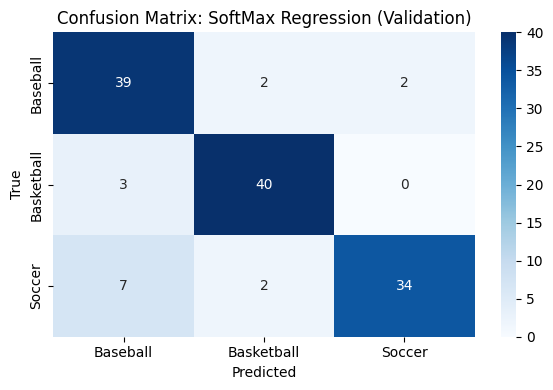


--- Final Test Results ---
Accuracy: 0.8837
Macro F1: 0.8835

Classification Report:
               precision    recall  f1-score   support

    Baseball       0.86      0.86      0.86        43
  Basketball       0.85      0.95      0.90        43
      Soccer       0.95      0.84      0.89        43

    accuracy                           0.88       129
   macro avg       0.89      0.88      0.88       129
weighted avg       0.89      0.88      0.88       129



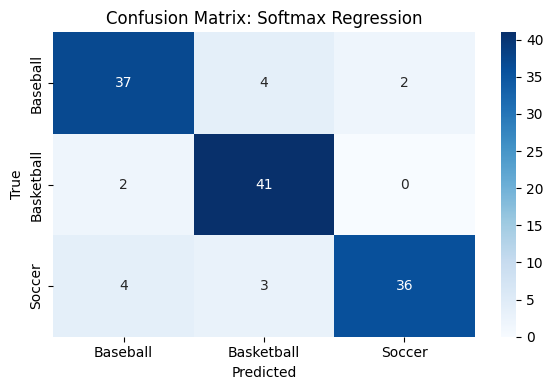

In [3]:
from sklearn.linear_model import LogisticRegression

print("==================================================")
print("1. SOFTMAX REGRESSION: TUNING & EVALUATION")
print("==================================================")

C_values = [0.01, 0.1, 1, 10, 100]
N_train = len(X_train)

best_f1 = 0
best_params = {}
best_model = None

# --- Tuning ---
for C_val in C_values:
    # Exact mapping from average cross-entropy + lambda_val * ||W||_F^2 to sklearn's C
    lambda_val = 1.0 / (N_train * C_val)
    
    clf = LogisticRegression(solver='lbfgs', C=C_val, max_iter=1000, tol=0.0001, random_state=42)
    clf.fit(X_train, y_train)
    y_val_pred = clf.predict(X_val)
    
    val_acc = accuracy_score(y_val, y_val_pred)
    val_f1 = f1_score(y_val, y_val_pred, average='macro')
    print(f"C: {C_val:<6} (lambda_val: {lambda_val:.6e}) | Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_params = {'C': C_val, 'lambda_val': lambda_val}
        best_model = clf

# --- Export ---
with open('models/softmax_weights.json', 'w') as f:
    json.dump({
        'weights': best_model.coef_.tolist(),
        'biases': best_model.intercept_.tolist(),
        'classes': best_model.classes_.tolist()
    }, f)

print(f"\n>> BEST PARAMS: C={best_params['C']} (lambda_val={best_params['lambda_val']:.6e}) | Val Macro F1: {best_f1:.4f}")

# --- Validation Confusion Matrix for Model Selection ---
y_val_pred = best_model.predict(X_val)

plot_cm(y_val, y_val_pred, title="Confusion Matrix: SoftMax Regression (Validation)")


# --- Testing ---
y_test_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("\n--- Final Test Results ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"Macro F1: {test_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_test_pred, target_names=['Baseball', 'Basketball', 'Soccer']))

plot_cm(y_test, y_test_pred, title="Confusion Matrix: Softmax Regression")

#### 3. Random Forest

2. RANDOM FOREST: TUNING & EVALUATION
n_est: 100, depth: 10, min_leaf: 1, max_feat: sqrt | Val Acc: 0.8527 | Val Macro F1: 0.8525
n_est: 100, depth: 10, min_leaf: 1, max_feat: 0.1 | Val Acc: 0.8450 | Val Macro F1: 0.8430
n_est: 100, depth: 10, min_leaf: 2, max_feat: sqrt | Val Acc: 0.8450 | Val Macro F1: 0.8456
n_est: 100, depth: 10, min_leaf: 2, max_feat: 0.1 | Val Acc: 0.8605 | Val Macro F1: 0.8598
n_est: 100, depth: 10, min_leaf: 5, max_feat: sqrt | Val Acc: 0.8217 | Val Macro F1: 0.8216
n_est: 100, depth: 10, min_leaf: 5, max_feat: 0.1 | Val Acc: 0.8527 | Val Macro F1: 0.8522
n_est: 100, depth: 20, min_leaf: 1, max_feat: sqrt | Val Acc: 0.8450 | Val Macro F1: 0.8449
n_est: 100, depth: 20, min_leaf: 1, max_feat: 0.1 | Val Acc: 0.8527 | Val Macro F1: 0.8526
n_est: 100, depth: 20, min_leaf: 2, max_feat: sqrt | Val Acc: 0.8372 | Val Macro F1: 0.8370
n_est: 100, depth: 20, min_leaf: 2, max_feat: 0.1 | Val Acc: 0.8527 | Val Macro F1: 0.8518
n_est: 100, depth: 20, min_leaf: 5, max_feat: s

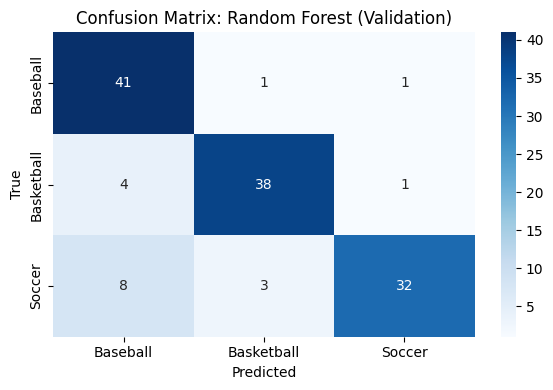


--- Final Test Results ---
Accuracy: 0.8760
Macro F1: 0.8763

Classification Report:
               precision    recall  f1-score   support

    Baseball       0.83      0.91      0.87        43
  Basketball       0.83      0.93      0.88        43
      Soccer       1.00      0.79      0.88        43

    accuracy                           0.88       129
   macro avg       0.89      0.88      0.88       129
weighted avg       0.89      0.88      0.88       129



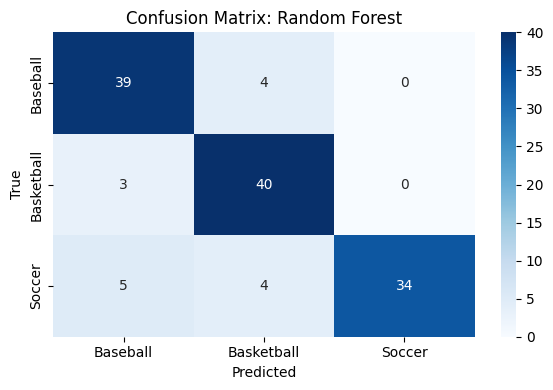

In [4]:
import os
import json
import joblib
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

print("==================================================")
print("2. RANDOM FOREST: TUNING & EVALUATION")
print("==================================================")

rf_n_estimators = [100, 200, 300, 400]
rf_max_depth = [10, 20, None]
rf_min_samples_leaf = [1, 2, 5]
rf_max_features = ['sqrt', 0.1] 

best_f1 = 0
best_params = {}
best_model = None

# --- Tuning ---
for n_est in rf_n_estimators:
    for depth in rf_max_depth:
        for min_leaf in rf_min_samples_leaf:
            for max_feat in rf_max_features:
                rf = RandomForestClassifier(n_estimators=n_est, max_depth=depth,
                                            min_samples_leaf=min_leaf, max_features=max_feat,
                                            random_state=42, n_jobs=-1)
                rf.fit(X_train, y_train)
                y_val_pred = rf.predict(X_val)
                
                val_acc = accuracy_score(y_val, y_val_pred)
                val_f1 = f1_score(y_val, y_val_pred, average='macro')
                print(f"n_est: {n_est}, depth: {depth}, min_leaf: {min_leaf}, max_feat: {max_feat} "
                      f"| Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
                
                if val_f1 > best_f1:
                    best_f1 = val_f1
                    best_params = {'n_estimators': n_est, 'max_depth': depth, 
                                   'min_samples_leaf': min_leaf, 'max_features': max_feat}
                    best_model = rf

# --- Export ---
rf_json_data = {
    'classes': best_model.classes_.tolist(),
    'trees': []
}

for estimator in best_model.estimators_:
    tree = estimator.tree_
    tree_dict = {
        'children_left': tree.children_left.tolist(),
        'children_right': tree.children_right.tolist(),
        'feature': tree.feature.tolist(),
        'threshold': tree.threshold.tolist(),
        'value': tree.value.tolist()  # Contains class distributions at each node
    }
    rf_json_data['trees'].append(tree_dict)

with open('models/rf_weights.json', 'w') as f:
    json.dump(rf_json_data, f)

print(f"\n>> BEST PARAMS SAVED (joblib & json): {best_params} | Val Macro F1: {best_f1:.4f}")

# --- Validation Confusion Matrix for Model Selection ---
y_val_pred = best_model.predict(X_val)

plot_cm(y_val, y_val_pred, title="Confusion Matrix: Random Forest (Validation)")


# --- Testing ---
y_test_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("\n--- Final Test Results ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"Macro F1: {test_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_test_pred, target_names=['Baseball', 'Basketball', 'Soccer']))

plot_cm(y_test, y_test_pred, title="Confusion Matrix: Random Forest")

#### 4. MLP

3. MULTILAYER PERCEPTRON (MLP): TUNING & EVALUATION
Arch: (32,), Alpha: 0.0001 | Val Acc: 0.8372 | Val Macro F1: 0.8366
Arch: (32,), Alpha: 0.01 | Val Acc: 0.8295 | Val Macro F1: 0.8281
Arch: (32,), Alpha: 0.1 | Val Acc: 0.8372 | Val Macro F1: 0.8369
Arch: (64,), Alpha: 0.0001 | Val Acc: 0.8295 | Val Macro F1: 0.8296
Arch: (64,), Alpha: 0.01 | Val Acc: 0.8295 | Val Macro F1: 0.8296
Arch: (64,), Alpha: 0.1 | Val Acc: 0.8372 | Val Macro F1: 0.8372
Arch: (32, 16), Alpha: 0.0001 | Val Acc: 0.8450 | Val Macro F1: 0.8438
Arch: (32, 16), Alpha: 0.01 | Val Acc: 0.8682 | Val Macro F1: 0.8675
Arch: (32, 16), Alpha: 0.1 | Val Acc: 0.8760 | Val Macro F1: 0.8760

>> BEST PARAMS: {'hidden_layer_sizes': (32, 16), 'alpha': 0.1} | Val Macro F1: 0.8760


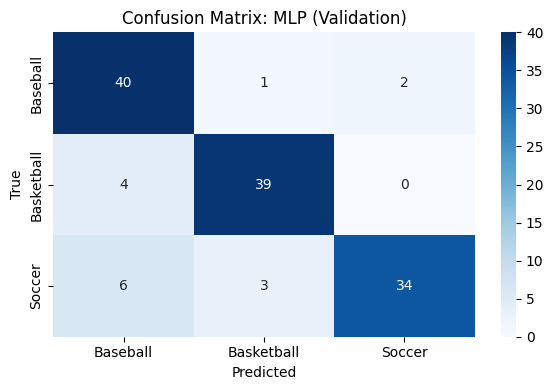


--- Final Test Results ---
Accuracy: 0.8992
Macro F1: 0.8991

Classification Report:
               precision    recall  f1-score   support

    Baseball       0.88      0.88      0.88        43
  Basketball       0.87      0.95      0.91        43
      Soccer       0.95      0.86      0.90        43

    accuracy                           0.90       129
   macro avg       0.90      0.90      0.90       129
weighted avg       0.90      0.90      0.90       129



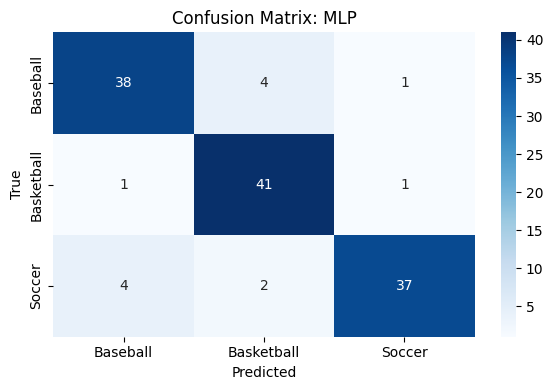

In [5]:
from sklearn.neural_network import MLPClassifier

print("==================================================")
print("3. MULTILAYER PERCEPTRON (MLP): TUNING & EVALUATION")
print("==================================================")

mlp_architectures = [(32,), (64,), (32, 16)]
mlp_alphas = [0.0001, 0.01, 0.1]

best_f1 = 0
best_params = {}
best_model = None

# --- Tuning ---
for arch in mlp_architectures:
    for alpha in mlp_alphas:
        mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu', solver='adam',
                            alpha=alpha, learning_rate_init=0.001, max_iter=1000, random_state=42)
        mlp.fit(X_train, y_train)
        y_val_pred = mlp.predict(X_val)
        
        val_acc = accuracy_score(y_val, y_val_pred)
        val_f1 = f1_score(y_val, y_val_pred, average='macro')
        print(f"Arch: {arch}, Alpha: {alpha} | Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")
        
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_params = {'hidden_layer_sizes': arch, 'alpha': alpha}
            best_model = mlp

# --- Export ---
with open('models/mlp_weights.json', 'w') as f:
    json.dump({
        'weights': [w.tolist() for w in best_model.coefs_],
        'biases': [b.tolist() for b in best_model.intercepts_],
        'classes': best_model.classes_.tolist()
    }, f)

print(f"\n>> BEST PARAMS: {best_params} | Val Macro F1: {best_f1:.4f}")

# --- Validation Confusion Matrix for Model Selection ---
y_val_pred = best_model.predict(X_val)

plot_cm(y_val, y_val_pred, title="Confusion Matrix: MLP (Validation)")

# --- Testing ---
y_test_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("\n--- Final Test Results ---")
print(f"Accuracy: {test_acc:.4f}")
print(f"Macro F1: {test_f1:.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_test_pred, target_names=['Baseball', 'Basketball', 'Soccer']))

plot_cm(y_test, y_test_pred, title="Confusion Matrix: MLP")